# LLMy w praktyce – zajęcia 1
## Tekst, tokeny i pierwszy model językowy

## O czym są te zajęcia i dlaczego to ważne?

Duży model językowy (LLM), np. GPT, robi **jedną rzecz**: na podstawie dotychczasowego tekstu
**przewiduje następny token**. Cała odpowiedź czatu powstaje przez powtórzenie tego kroku setki razy:

```
"Ala ma"  ->  model  ->  " kota"
"Ala ma kota"  ->  model  ->  "."
...
```

Żeby to było możliwe, model musi:
1. pociąć tekst na **tokeny** (kawałki tekstu),
2. zamienić tokeny na **liczby**,
3. znać **statystykę języka** – które tokeny zwykle występują po których.

**Na dzisiejszych zajęciach:**
- zobaczymy, jak tekst „widzi” prawdziwy model GPT-2 (tokenizer BPE),
- przećwiczymy klasyczne przetwarzanie tekstu: normalizację, tokenizację, liczenie słów,
- zmierzymy, **ile informacji niesie słowo** – to jest podstawa funkcji straty, którą trenuje się LLM-y,
- zbudujemy **pierwszy model językowy – model bigramowy**, który generuje tekst *tą samą pętlą co GPT*,
  tylko z dużo prostszym „mózgiem”.

**Dlaczego to ważne?** Wszystko, co zrobimy w kolejnych tygodniach (embeddingi, sieci neuronowe,
mechanizm uwagi, GPT), to coraz lepszy sposób na policzenie jednej wielkości:

$$P(\text{następny token} \mid \text{wcześniejszy tekst})$$

Dzisiaj liczymy ją najprostszą możliwą metodą – **zliczając**.

**Plan (ok. 90 min):**

| Część | Temat | Czas |
|---|---|---|
| 1 | Jak tekst widzi GPT? | 10 min |
| 2–4 | Znaki, normalizacja, tokenizacja | 20 min |
| 5–6 | Częstości słów, informacja, stop-words | 15 min |
| 7–8 | n-gramy, słownik i indeksy | 15 min |
| 9 | **Pierwszy model językowy (bigramowy)** | 25 min |
| 10 | Podsumowanie | 5 min |

Na końcu notatnika są **zadania domowe**.

### Słownik pojęć
- **Znak (character)** – pojedynczy symbol: litera, cyfra, spacja, kropka.
- **Słowo** – fragment tekstu oddzielony spacjami.
- **Token** – jednostka, na której pracuje model. Może to być słowo, fragment słowa, znak, a nawet pojedynczy bajt.
- **Tokenizacja** – podział tekstu na tokeny.
- **Normalizacja** – ujednolicenie tekstu (małe litery, usunięcie interpunkcji, nadmiarowych spacji).
- **Słownik (vocabulary)** – zbiór wszystkich różnych tokenów, które zna model. Każdy token ma swój numer (indeks).
- **Stop-words** – bardzo częste słowa o małej treści („the”, „and”, „of”).
- **n-gram** – ciąg *n* kolejnych tokenów: unigram (1), bigram (2), trigram (3).
- **Model językowy** – model, który przypisuje prawdopodobieństwo następnemu tokenowi: $P(w_{t} \mid w_1, \dots, w_{t-1})$.
- **Embedding** – reprezentacja tokenu jako wektor liczb (temat następnych zajęć).

In [31]:
# Importy używane w notatniku
import re
import math
import random
from collections import Counter, defaultdict
import matplotlib.pyplot as plt

print("Imports OK")

Imports OK


## 1. Jak tekst widzi GPT?

Zacznijmy od końca: zobaczmy, jak prawdziwy model **GPT-2** dzieli tekst na tokeny.
Używa do tego tokenizera **BPE** (*Byte Pair Encoding*). Jego słownik ma **50 257 tokenów**.
Każdy token ma swój numer (ID) – i **tylko te numery trafiają do sieci neuronowej**.

In [32]:
!pip install -q tiktoken

In [33]:
import tiktoken

enc = tiktoken.get_encoding("gpt2")   # tokenizer modelu GPT-2
print("Rozmiar słownika GPT-2:", enc.n_vocab)

def show_tokens(sentence):
    ids = enc.encode(sentence)                 # tekst -> lista numerów tokenów
    pieces = [enc.decode([i]) for i in ids]    # każdy numer z powrotem na tekst
    print(f"Tekst:  {sentence}")
    print(f"Słów: {len(sentence.split())}, tokenów: {len(ids)}")
    print(f"ID:     {ids}")
    print(f"Tokeny: {pieces}\n")

show_tokens("Machine learning models are now used in many fields.")
show_tokens("Modele uczenia maszynowego są dziś używane w wielu dziedzinach.")

Rozmiar słownika GPT-2: 50257
Tekst:  Machine learning models are now used in many fields.
Słów: 9, tokenów: 10
ID:     [37573, 4673, 4981, 389, 783, 973, 287, 867, 7032, 13]
Tokeny: ['Machine', ' learning', ' models', ' are', ' now', ' used', ' in', ' many', ' fields', '.']

Tekst:  Modele uczenia maszynowego są dziś używane w wielu dziedzinach.
Słów: 9, tokenów: 35
ID:     [19076, 293, 334, 66, 4801, 544, 12422, 89, 2047, 322, 1533, 78, 264, 128, 227, 288, 17027, 129, 249, 334, 129, 120, 88, 86, 1531, 266, 266, 8207, 84, 288, 89, 798, 42140, 620, 13]
Tokeny: ['Mode', 'le', ' u', 'c', 'zen', 'ia', ' mas', 'z', 'yn', 'ow', 'eg', 'o', ' s', '�', '�', ' d', 'zi', '�', '�', ' u', '�', '�', 'y', 'w', 'ane', ' w', ' w', 'iel', 'u', ' d', 'z', 'ied', 'zin', 'ach', '.']



**Na co zwrócić uwagę:**
- Spacja jest **częścią tokenu** (`' learning'`). Dla modelu „learning” na początku zdania i „ learning” w środku to *różne* tokeny.
- Polskie zdanie ma tyle samo słów, ale **dużo więcej tokenów**. Tokenizer GPT-2 uczono głównie na tekstach angielskich, więc polskie słowa rozpadają się na małe kawałki.
- Znaki `�` pojawiają się, bo litery `ą`, `ż` zapisuje się w UTF-8 jako **2 bajty**, a tokenizer GPT-2 pociął je na pojedyncze bajty. Jeden bajt sam w sobie nie jest poprawnym znakiem.

### Zadanie 1
1. Ile słów i ile tokenów ma każde zdanie? Skąd bierze się różnica?
2. Sprawdź tokenizację: swojego imienia, liczby `2026`, liczby `123456789`, słowa `nieprawdopodobnie` i jakiegoś emoji (np. `🙂`).
3. GPT-2 widzi naraz maksymalnie **1024 tokeny** (tzw. *okno kontekstu*). Co to oznacza dla tekstów po polsku w porównaniu z angielskimi?

In [34]:
# TODO: punkt 2 – użyj funkcji show_tokens()
show_tokens("Jakub")
show_tokens("2026")
show_tokens("123456789")
show_tokens("nieprawdopodobnie")
show_tokens("🙂")

Tekst:  Jakub
Słów: 1, tokenów: 3
ID:     [41, 461, 549]
Tokeny: ['J', 'ak', 'ub']

Tekst:  2026
Słów: 1, tokenów: 2
ID:     [1238, 2075]
Tokeny: ['20', '26']

Tekst:  123456789
Słów: 1, tokenów: 4
ID:     [10163, 2231, 3134, 4531]
Tokeny: ['123', '45', '67', '89']

Tekst:  nieprawdopodobnie
Słów: 1, tokenów: 8
ID:     [11952, 79, 1831, 67, 404, 375, 672, 11952]
Tokeny: ['nie', 'p', 'raw', 'd', 'op', 'od', 'ob', 'nie']

Tekst:  🙂
Słów: 1, tokenów: 2
ID:     [8582, 25081]
Tokeny: ['�', '��']



**Odpowiedzi:** 1. to zależy w jakim języku gdyż modele były trenowane w języku angielskim więc mniej będzie tokenów potrzebnych w tym właśnie języku niż np w polskim dodatkowo liczone są znaki interpunkcyjne
3. że mniej będzie mógł przetworzyć, niższa efektywność tokenizacji języka polskiego, Problem „zapominania” i krótsza pamięć operacyjna

*(miejsce na Twoje odpowiedzi)*

## 2. Dane wejściowe: znaki i słowa

Na zajęciach pracujemy z krótkim tekstem o uczeniu maszynowym. To nasz mini-**korpus**
(zbiór tekstów, na którym „uczymy” model).

In [35]:
text = """Machine learning is a field of artificial intelligence that focuses on building systems able to learn from data.
A machine learning model improves its performance as it receives more data and feedback.
In supervised learning, the model is trained on labeled examples, while in unsupervised learning it tries to find patterns without labels.
Neural networks are one of the most popular methods in modern machine learning.
A neural network consists of layers of artificial neurons that process information step by step.
Each neuron receives input values, multiplies them by weights, and applies an activation function.
The output of one layer becomes the input of the next layer.
This structure allows the network to learn complex patterns and representations.

Training a neural network requires a dataset, a loss function, and an optimization algorithm.
During training, the model makes predictions, compares them with real labels, and updates the weights to reduce the error.
This process is repeated many times until the model reaches satisfactory accuracy.
In deep learning, networks have many layers and can handle complex tasks such as image recognition or natural language processing.
For example, a convolutional neural network can identify shapes and textures in pictures, while a recurrent neural network can process sequences of words in a sentence.
Both models learn by minimizing loss and adjusting weights through backpropagation.

Data plays a central role in machine learning.
The quality, diversity, and amount of data determine how well the model generalizes to new situations.
If the dataset is too small or biased, the model may memorize examples instead of learning general patterns.
Therefore, data preprocessing, normalization, and augmentation are crucial steps before training.
Once a model is trained, it can be evaluated on a separate test set to estimate its real performance.
Machine learning models are now used in many fields: medicine, finance, marketing, and robotics.
They help detect diseases, predict stock prices, recommend products, and control autonomous vehicles."""

print("Liczba znaków:", len(text))
print("Liczba słów (split):", len(text.split()))

Liczba znaków: 2102
Liczba słów (split): 319


### Zadanie 2
1. Czym różni się *znak* od *słowa*? Co liczy `len(text)`, a co `len(text.split())`?
2. Czy `len(text)` zawsze rośnie razem z liczbą słów? Podaj przykład dwóch tekstów, dla których jest inaczej.

**Odpowiedzi:** 1. Znak to dowolny pojedyńczy element w tekście, len(text) liczy całkowitą liczbę znaków natomiast len(text.split()) liczy całe słowa, domyślnie dzieli tekst po białych znakach.
2. tak zawsze rośnie gdyż jak dodamy do danego słowa następne słowo len(text) pokaże w każdym przypadku większy wynik natomiast jeśli chodzi o porównanie tekstów czy zawsze tekst z większą liczbą słów zwróci większe wartości z len(text) to jest to nie prawda przykładem jest ("A B C D") z ("programowanie")

*(miejsce na Twoje odpowiedzi)*

## 3. Normalizacja

**Normalizacja** to ujednolicenie tekstu, żeby różne zapisy tego samego słowa liczyły się razem
(`Machine`, `machine`, `machine.` → `machine`). Zrobimy trzy kroki:
1. zamiana na małe litery,
2. zamiana wszystkiego, co nie jest literą ani spacją, na spację (wyrażenie regularne),
3. zamiana wielu białych znaków na jedną spację i usunięcie spacji z początku i końca.

W wyrażeniu regularnym dopisaliśmy polskie litery – inaczej słowo „uczenie” przetrwa, ale „są” zamieni się w „s”.

In [36]:
def normalize(t):
    t = t.lower()                               # 1. małe litery
    t = re.sub(r"[^a-ząćęłńóśźż ]", " ", t)     # 2. tylko litery (także polskie) i spacje
    t = re.sub(r"\s+", " ", t).strip()          # 3. jedna spacja między słowami, bez spacji na brzegach
    return t

clean = normalize(text)
print(clean[:300], "...")

machine learning is a field of artificial intelligence that focuses on building systems able to learn from data a machine learning model improves its performance as it receives more data and feedback in supervised learning the model is trained on labeled examples while in unsupervised learning it tr ...


> **Ważne:** LLM-y **nie** normalizują tekstu w ten sposób. Dla GPT `Apple` i `apple` to różne tokeny, a kropka czy przecinek
> to też tokeny – i dobrze, bo niosą informację (początek zdania, nazwa własna, intonacja pytania).
> Normalizacja przydaje się w **klasycznym NLP** i przy małych danych, gdy chcemy policzyć statystyki słów.

### Zadanie 3
1. Co oznacza wzorzec `[^a-ząćęłńóśźż ]`? (Podpowiedź: co robi `^` na początku nawiasu kwadratowego?)
2. Po co jest krok 3 (`\s+` → `" "` i `strip()`)? Co by się stało bez niego?
3. Sprawdź, co funkcja `normalize` zrobi z tekstem: `"Don't send e-mails after 22:30, it's GPT-3.5!"`. Jakie informacje zostały utracone?

In [37]:
# TODO: punkt 3
normalize("Don't send e-mails after 22:30, it's GPT-3.5!")

'don t send e mails after it s gpt'

**Odpowiedzi:** 1. Znak daszka (^) umieszczony bezpośrednio po otwierającym nawiasie kwadratowym oznacza negację zbioru znaków. Cały wzorzec dopasowuje każdy pojedynczy znak, który NIE jest małą literą alfabetu łacińskiego
2. \s+ → " " scala dowolny ciąg białych znaków (wielu spacji, tabulatorów, znaków nowej linii) w jedną pojedynczą spację. strip() usuwa zbędne białe znaki z początku i końca całego napisu. Bez tego kroku: w wynikowym tekście mielibyśmy liczne podwójne/potrójne spacje (np. "after  " po usunięciu cyfr i dwukropka) oraz wiszące spacje na brzegach tekstu, co przy późniejszym dzieleniu tekstu na słowa (np. przez .split(" ")) generowałoby puste stringi "" jako fałszywe tokeny.
3. Liczby i dane numeryczne, Struktura skrótów i złożeń: apostrofy i myślniki zostały zamienione na spacje, co sztucznie rozbiło pojedyncze wyrazy na osobne fragmenty, Wielkość liter, Interpunkcja i intonacja


*(miejsce na Twoje odpowiedzi)*

## 4. Tokenizacja: słowa, znaki czy BPE?

**Tokenizacja** to podział tekstu na tokeny. Najprostsza wersja to podział po spacjach (`split()`).
Ale to nie jedyna możliwość. Porównajmy trzy podejścia:

| Tokenizacja | Przykład | Zaleta | Wada |
|---|---|---|---|
| **słowa** | `["neural", "networks"]` | krótkie sekwencje | ogromny słownik, nowe słowa są nieznane |
| **znaki** | `["n","e","u",...]` | mały słownik, brak nieznanych słów | bardzo długie sekwencje |
| **BPE** (GPT) | `["neural", " networks"]` | kompromis | trzeba ją wcześniej „wytrenować” na korpusie |

In [38]:
words = clean.split()     # tokenizacja słowna
print("Pierwsze 10 tokenów:", words[:10])
print("Liczba tokenów:", len(words))

Pierwsze 10 tokenów: ['machine', 'learning', 'is', 'a', 'field', 'of', 'artificial', 'intelligence', 'that', 'focuses']
Liczba tokenów: 319


### Zadanie 4
Dla **całego tekstu `text`** policz i porównaj w tabeli:
- liczbę tokenów,
- rozmiar słownika (liczbę **różnych** tokenów),

dla trzech tokenizacji: słownej (`words`), znakowej (`list(clean)`) i BPE (`enc.encode(text)`).

Pytania:
1. Która tokenizacja daje najdłuższe sekwencje, a która największy słownik?
2. Dlaczego modele typu GPT nie używają tokenizacji słownej? (Pomyśl o słowie, którego nie było w danych treningowych.)

In [39]:
# TODO: policz liczbę tokenów i rozmiar słownika dla trzech tokenizacji
# 1. Słowna (words)
n_tokens_words = len(words)
vocab_words = len(set(words))

# 2. Znakowa (list(clean))
chars = list(clean)
n_tokens_chars = len(chars)
vocab_chars = len(set(chars))

# 3. BPE (enc.encode(text))
bpe_tokens = enc.encode(text)
n_tokens_bpe = len(bpe_tokens)
vocab_bpe = len(set(bpe_tokens))

# Tabela porównawcza
print(f"| Tokenizacja         | Liczba tokenów | Rozmiar słownika (unikalne) |")
print(f"|---------------------|----------------|-----------------------------|")
print(f"| Słowna (words)      | {n_tokens_words:<14} | {vocab_words:<27} |")
print(f"| Znakowa (list)      | {n_tokens_chars:<14} | {vocab_chars:<27} |")
print(f"| BPE (enc.encode)    | {n_tokens_bpe:<14} | {vocab_bpe} (słownik: {enc.n_vocab}) |")

| Tokenizacja         | Liczba tokenów | Rozmiar słownika (unikalne) |
|---------------------|----------------|-----------------------------|
| Słowna (words)      | 319            | 181                         |
| Znakowa (list)      | 2053           | 27                          |
| BPE (enc.encode)    | 402            | 205 (słownik: 50257) |


**Odpowiedzi:**
1. Najdłuższe sekwencje (najwięcej tokenów w tekście): Daje tokenizacja znakowa. Rozbija ona tekst na pojedyncze litery i spacje, przez co wygenerowana lista jest najdłuższa. Największy słownik (liczba możliwych różnych tokenów): Daje tokenizacja słowna. Język naturalny ma potencjalnie nieskończoną liczbę słów (uwzględniając odmiany, błędy, neologizmy czy nazwy własne). Z kolei słownik znakowy to tylko kilkadziesiąt pozycji (alfabet + spacje), a słownik BPE jest z góry ustalony (dla GPT-2 to 50 257 tokenów).
2. Modele oparte na Transformerach nie używają tokenizacji słownej z powodu problemu OOV (Out-Of-Vocabulary), czyli słów spoza słownika. Jeśli w danych treningowych nie było jakiegoś konkretnego słowa (np. nowej nazwy własnej, specyficznego błędu ortograficznego lub rzadkiej odmiany wyrazu), model oparty na słowach nie wiedziałby, jak je przetworzyć
*(miejsce na Twoje odpowiedzi)*

## 5. Częstości słów i ilość informacji

Policzmy, jak często występuje każde słowo. To pierwsza „statystyka języka”.

In [40]:
word_counts = Counter(words)
N = len(words)
print("Liczba tokenów N:", N)
print("Liczba różnych słów:", len(word_counts))
print("Top-10:", word_counts.most_common(10))

Liczba tokenów N: 319
Liczba różnych słów: 181
Top-10: [('the', 14), ('a', 12), ('and', 12), ('learning', 9), ('of', 9), ('in', 8), ('model', 7), ('to', 6), ('machine', 5), ('is', 5)]


### Ile informacji niesie słowo?

Prawdopodobieństwo słowa szacujemy jako jego częstość: $p(w) = \dfrac{\text{count}(w)}{N}$.

**Informacja Shannona** (inaczej: *zaskoczenie*) słowa to:
$$I(w) = -\log_2 p(w) \quad \text{[bity]}$$

- słowo częste (np. „the”) → $p$ duże → **mało** informacji (nie dziwi nas),
- słowo rzadkie (np. „backpropagation”) → $p$ małe → **dużo** informacji.

> **Most do LLM-ów:** podczas treningu LLM dostaje dla każdego tokenu „karę” równą $-\log p(\text{prawdziwy następny token})$,
> czyli dokładnie **zaskoczenie** modelu. Model, który dobrze przewiduje, rzadko jest zaskoczony i ma małą karę.
> Średnia z tych kar to funkcja straty **cross-entropy**, którą zobaczymy w PyTorchu.

In [41]:
def information(word):
    p = word_counts[word] / N
    return -math.log2(p)

for w in ["the", "learning", "network", "backpropagation"]:
    print(f"{w:<16} count={word_counts[w]:>2}  p={word_counts[w]/N:.4f}  I={information(w):.2f} bitów")

the              count=14  p=0.0439  I=4.51 bitów
learning         count= 9  p=0.0282  I=5.15 bitów
network          count= 5  p=0.0157  I=6.00 bitów
backpropagation  count= 1  p=0.0031  I=8.32 bitów


### Zadanie 5
1. Które słowa w tekście niosą **najmniej**, a które **najwięcej** informacji? Ile różnych słów ma maksymalną informację?
2. Jaka jest najmniejsza możliwa wartość $I(w)$ i kiedy ją osiągamy?
3. **Entropia** to średnia informacja: $H = -\sum_w p(w)\log_2 p(w)$. Policz $H$ dla naszego tekstu.
   (Interpretacja: ile bitów średnio potrzeba, żeby „zakodować” jedno słowo.)

In [42]:
# TODO: punkt 1 i 3

# --- PUNKT 1: Słowa niosące najmniej i najwięcej informacji ---
# Najmniejszą informację niosą słowa najczęstsze (najwyższy count)
# Największą informację niosą słowa najrzadsze (count = 1)
min_count = min(word_counts.values())
max_count = max(word_counts.values())

najczestsze = [word for word, count in word_counts.items() if count == max_count]
najrzadsze = [word for word, count in word_counts.items() if count == min_count]

print("--- PUNKT 1 ---")
print(f"Słowa najczęstsze (najmniej informacji): {najczestsze} (wystąpienia: {max_count})")
print(f"Słowa najrzadsze (najwięcej informacji):")
print(f"Liczba słów z maksymalną informacją (występujących 1 raz): {len(najrzadsze)}")
print(f"Przykłady słów najrzadszych (pierwsze 10): {najrzadsze[:10]}\n")

# --- PUNKT 3: Entropia H dla całego tekstu ---
# H = - sum( p(w) * log2(p(w)) )
entropy = 0
for word, count in word_counts.items():
    p = count / N
    entropy -= p * math.log2(p)

print("--- PUNKT 3 ---")
print(f"Entropia H całego tekstu: {entropy:.4f} bitów")

--- PUNKT 1 ---
Słowa najczęstsze (najmniej informacji): ['the'] (wystąpienia: 14)
Słowa najrzadsze (najwięcej informacji):
Liczba słów z maksymalną informacją (występujących 1 raz): 131
Przykłady słów najrzadszych (pierwsze 10): ['field', 'intelligence', 'focuses', 'building', 'systems', 'able', 'from', 'improves', 'more', 'feedback']

--- PUNKT 3 ---
Entropia H całego tekstu: 6.9972 bitów


**Odpowiedzi:**
Najmniej nosią słowa takie jak the gdyż wystąpiły najwięcej razy gdyż mają największe prawdopodobieństwo, natomiast najwięcej informacji niosą słowa najrzadsze np feedback, 131 słów ma maksymalną informację.
2. wynosi 0 (lub zbliża się do 0, gdy prawdopodobieństwo p(w) = 1)
3. H=6.9972, średnio potrzeba właśnie tyle bitów informacji, aby „zakodować” lub przewidzieć jedno losowe słowo z tego tekstu.

*(miejsce na Twoje odpowiedzi)*

## 6. Stop-words

**Stop-words** to bardzo częste słowa funkcyjne („the”, „a”, „and”, „of”). W klasycznym NLP często się je usuwa,
żeby zostały słowa „treściowe”.

In [43]:
stop_words = {"the", "a", "an", "and", "of", "in", "on", "to", "it", "is", "are",
              "by", "as", "that", "this", "its", "or", "with", "can", "from"}
filtered = [w for w in words if w not in stop_words]

print("Tokenów przed:", len(words), " po:", len(filtered))
print("Top-10 po filtracji:", Counter(filtered).most_common(10))

Tokenów przed: 319  po: 223
Top-10 po filtracji: [('learning', 9), ('model', 7), ('machine', 5), ('data', 5), ('neural', 5), ('network', 5), ('learn', 3), ('patterns', 3), ('process', 3), ('weights', 3)]


### Zadanie 6
1. Jak zmieniła się lista top-10 po usunięciu stop-words? O czym jest tekst?
2. Podaj przykład zadania, w którym usunięcie stop-words **pomaga**, i takiego, w którym **szkodzi**.
   (Podpowiedź: porównaj zdania „this movie is good” i „this movie is not good” – czy „not” to stop-word?)
3. Dlaczego LLM-y (GPT) **nie** usuwają stop-words?

**Odpowiedzi:**
Po ich usunięciu na liście top-10 znalazły się wyłącznie merytoryczne słowa kluczowe (tzw. słowa treściowe), Usunięcie stop-words drastycznie zmienia strukturę i płynność tekstu, co sprawia, że tracimy kontekst gramatyczny i naturalne powiązania między słowami.
2. Pomaga w zadaniach takich jak wykrywanie głównych tematów dokumentu, Szkodzi w zadaniach wymagających zrozumienia kontekstu i logiki wypowiedzi. porównując zdania z przykladu, słowo "not" często kwalifikuje się jako stop-word, ale jego usunięcie całkowicie zmieniłoby sens
3. gdyż spójniki są kluczowe do zrozumienia relacji między słowami i mogłoby to generować sporo błędów
*(miejsce na Twoje odpowiedzi)*

## 7. n-gramy: sąsiedztwo słów

**n-gram** to ciąg *n* kolejnych tokenów. Dla zdania „ala ma kota”:
- unigramy: `ala`, `ma`, `kota`
- bigramy: `ala ma`, `ma kota`
- trigramy: `ala ma kota`

Bigramy mówią nam, **które słowa występują obok siebie**. To jest dokładnie ta informacja,
której potrzebujemy, żeby przewidywać następne słowo. Liczymy je na pełnej liście `words` (ze stop-words).

In [44]:
bigrams = list(zip(words[:-1], words[1:]))     # pary (słowo, następne słowo)
bigram_counts = Counter(bigrams)
print("Liczba bigramów:", len(bigrams))
print("Top-10 bigramów:", bigram_counts.most_common(10))

Liczba bigramów: 318
Top-10 bigramów: [(('machine', 'learning'), 5), (('the', 'model'), 5), (('neural', 'network'), 4), (('of', 'artificial'), 2), (('to', 'learn'), 2), (('learning', 'the'), 2), (('model', 'is'), 2), (('is', 'trained'), 2), (('of', 'the'), 2), (('a', 'neural'), 2)]


### Zadanie 7
1. Ile jest bigramów, jeśli mamy $N$ tokenów? Sprawdź na wyniku.
2. Wygeneruj **trigramy**. Ile ich jest? Wypisz top-5.
3. Znajdź w liście bigramów przykład pary, która **nie jest** naturalnym sąsiedztwem słów. Skąd się wzięła?
   (Podpowiedź: co się stało z kropkami na końcach zdań?)

In [45]:
# TODO: punkt 2 i 3
# --- PUNKT 1: Liczba bigramów a N tokenów ---
N_tokens = len(words)
liczba_bigramow = len(bigrams)
print(f"Liczba tokenów N: {N_tokens}")
print(f"Liczba bigramów: {liczba_bigramow} (zależność: N - 1)\n")

# --- PUNKT 2: Trigramy ---
trigrams = list(zip(words[:-2], words[1:-1], words[2:]))  # trójki słów
trigram_counts = Counter(trigrams)

print(f"Liczba trigramów: {len(trigrams)}")
print(f"Top-5 trigramów:")
for trigram, count in trigram_counts.most_common(5):
    print(f"  {trigram}: {count}")

Liczba tokenów N: 319
Liczba bigramów: 318 (zależność: N - 1)

Liczba trigramów: 317
Top-5 trigramów:
  ('model', 'is', 'trained'): 2
  ('a', 'neural', 'network'): 2
  ('neural', 'network', 'can'): 2
  ('machine', 'learning', 'is'): 1
  ('learning', 'is', 'a'): 1


**Odpowiedzi:**
1. mamy 318 bigramów
2. Top-5 trigramów:
  ('model', 'is', 'trained'): 2
  ('a', 'neural', 'network'): 2
  ('neural', 'network', 'can'): 2
  ('machine', 'learning', 'is'): 1
  ('learning', 'is', 'a'): 1
3. Para, w której ostatnie słowo jednego zdania stoi bezpośrednio obok pierwszego słowa następnego zdania np. ('data.', 'A') albo ('feedback.', 'In'), Podczas czyszczenia tekstu w poprzednich krokach usuwaliśmy interpunkcję (w tym kropki kończące zdania) lub dzieliliśmy tekst separatorem spacji. Ponieważ kropki zostały usunięte, koniec jednego zdania i początek drugiego „skleiły się” w jeden ciąg słów (words). Algorytm tworzący bigramy traktuje je liniowo, przez co łączy ostatnie słowo poprzedniego zdania z pierwszym słowem nowego zdania
*(miejsce na Twoje odpowiedzi)*

## 8. Słownik: tokeny → liczby

Sieć neuronowa nie rozumie tekstu – liczy na liczbach. Dlatego każdemu tokenowi przypisujemy **numer (indeks)**.
Dodajemy też specjalny token `<unk>` (*unknown*) na słowa, których nie ma w słowniku.

W GPT-2 jest dokładnie tak samo: słownik ma 50 257 pozycji, a do modelu trafiają same numery.
Na zajęciach 6 zobaczymy, jak numer zamienia się w wektor (`nn.Embedding`).

In [46]:
vocab = {"<unk>": 0}
for w in sorted(set(words)):
    vocab[w] = len(vocab)

print("Rozmiar słownika:", len(vocab))
print("Przykładowe pary:", list(vocab.items())[:8])

def encode(sentence):
    return [vocab.get(w, vocab["<unk>"]) for w in normalize(sentence).split()]

print(encode("Neural networks learn from data"))
print(encode("Neural networks learn from pizza"))

Rozmiar słownika: 182
Przykładowe pary: [('<unk>', 0), ('a', 1), ('able', 2), ('accuracy', 3), ('activation', 4), ('adjusting', 5), ('algorithm', 6), ('allows', 7)]
[100, 99, 79, 54, 33]
[100, 99, 79, 54, 0]


### Zadanie 8
1. Napisz funkcję `decode(ids)`, która zamienia listę numerów z powrotem na tekst. Sprawdź, czy `decode(encode(s))` daje zdanie `s`.
2. Co się dzieje ze słowem „pizza”? Dlaczego to problem?
3. Dlaczego tokenizer BPE z GPT-2 nie potrzebuje tokenu `<unk>`?

In [47]:
# TODO: funkcja decode
# Odwrócenie słownika: zamieniamy klucz-wartość (słowo -> ID) na (ID -> słowo)
id_to_word = {index: word for word, index in vocab.items()}

def decode(ids):
    # Dla każdego ID pobieramy słowo ze słownika, łącząc je spacjami w jeden tekst
    return " ".join([id_to_word.get(i, "<unk>") for i in ids])

# Sprawdzenie działania funkcji dla zdań z poprzedniego slajdu:
s1 = "Neural networks learn from data"
s2 = "Neural networks learn from pizza"

print("Test 1:", decode(encode(s1)))
print("Test 2:", decode(encode(s2)))

Test 1: neural networks learn from data
Test 2: neural networks learn from <unk>


**Odpowiedzi:**
1. Po zdefiniowaniu odwrotnego słownika i funkcji decode, wywołanie decode(encode(s)) zwraca tekst w formie oczyszczonej (zgodnej z funkcją normalize, czyli same małe litery, bez interpunkcji i ze znormalizowanymi spacjami). Jeśli zdanie wejściowe s zawierało wielkie litery lub kropki, wynikowy tekst różni się od oryginału brakiem tych elementów, ale pod względem słów jest w pełni zgodny.
2. Słowo "pizza" nie występuje w zbiorze treningowym tekstu, na którym zbudowano słownik vocab. W efekcie funkcja encode przypisuje mu indeks 0 (czyli token <unk> – unknown). Model traci specyficzną informację o tym, jakie dokładnie słowo tam się znajdowało. wiec nie bedzie miało znaczenia jaka informacje tam zawrzemy i tak zwróci ID 0
3. Ponieważ słownik GPT-2 zawiera podstawowe znaki i litery alfabetu, każdy nowy lub nieznany wyraz można zawsze bezpiecznie rozbić na mniejsze fragmenty lub pojedyncze litery, które znajdują się w słowniku. Dzięki temu tokenizer BPE nigdy nie napotka sytuacji, w której nie jest w stanie zakodować jakiegoś ciągu znaków.

*(miejsce na Twoje odpowiedzi)*

## 9. Pierwszy model językowy: model bigramowy

Teraz najważniejsza część zajęć. Zbudujemy model, który **przewiduje następne słowo**, czyli robi to samo co GPT.

**Pomysł:** następne słowo zależy tylko od bieżącego słowa. Prawdopodobieństwo liczymy z bigramów:

$$P(w_2 \mid w_1) = \frac{\text{count}(w_1\, w_2)}{\text{count}(w_1 \text{ jako pierwsze słowo bigramu})}$$

Przykład: jeśli po „neural” 4 razy było „network” i 1 raz „networks”, to
$P(\text{network} \mid \text{neural}) = 4/5 = 0{,}8$.

Taka **tabela prawdopodobieństw następnego słowa** to cały nasz model.
GPT liczy dokładnie taki sam rozkład – tylko siecią neuronową i na podstawie **całego** wcześniejszego tekstu, a nie jednego słowa.

In [48]:
# Dla każdego słowa zliczamy, jakie słowa występowały po nim
next_counts = defaultdict(Counter)
for w1, w2 in zip(words[:-1], words[1:]):
    next_counts[w1][w2] += 1

def next_word_probs(word):
    counts = next_counts[word]
    total = sum(counts.values())
    return {w: c / total for w, c in counts.most_common()}

print("Po 'neural':", next_word_probs("neural"))
print("Po 'the':   ", {w: round(p, 3) for w, p in next_word_probs("the").items()})

Po 'neural': {'network': 0.8, 'networks': 0.2}
Po 'the':    {'model': 0.357, 'most': 0.071, 'output': 0.071, 'input': 0.071, 'next': 0.071, 'network': 0.071, 'weights': 0.071, 'error': 0.071, 'quality': 0.071, 'dataset': 0.071}


### Jak generować tekst?

Generowanie to pętla – **ta sama, którą zobaczymy w GPT na zajęciach 8**:
1. weź bieżące słowo,
2. policz rozkład prawdopodobieństwa następnego słowa,
3. **wybierz** następne słowo,
4. dopisz je do tekstu i wróć do kroku 1.

Są dwie podstawowe strategie wyboru w kroku 3:
- **greedy (zachłanna)** – zawsze bierzemy najbardziej prawdopodobne słowo,
- **sampling (losowanie)** – losujemy słowo zgodnie z prawdopodobieństwami (częste słowa wypadają częściej, ale nie zawsze).

Do losowania przyda się funkcja `random.choices(lista, weights=wagi)`.

### Zadanie 9 (główne zadanie zajęć)
1. Uzupełnij funkcję `generate(seed, n, strategy)`, która startuje od słowa `seed` i dopisuje maksymalnie `n` słów.
   Jeśli bieżące słowo nie ma żadnego następcy – kończy wcześniej.
2. Wygeneruj tekst dla seedów `"machine"`, `"the"`, `"data"` (n = 15) obiema strategiami.
3. Odpowiedz:
   - Co się dzieje przy strategii **greedy**? Dlaczego?
   - Czym różnią się wyniki **sampling** przy kolejnych uruchomieniach?
   - Tekst z samplingu jest „lokalnie poprawny”, ale jako całość nie ma sensu. Dlaczego? Jak radzi sobie z tym GPT?

In [49]:
random.seed(42)   # żeby losowanie było powtarzalne

def generate(seed, n=15, strategy="greedy"):
    result = [seed]
    for _ in range(n):
        current = result[-1]
        probs = next_word_probs(current)
        if not probs:                 # brak następców – koniec
            break
        if strategy == "greedy":
            next_word = list(probs.keys())[0]     # TODO: słowo o największym prawdopodobieństwie
        else:
            next_word = random.choices(list(probs.keys()), weights=list(probs.values()))[0]# TODO: losowanie zgodnie z prawdopodobieństwami
        result.append(next_word)
    return " ".join(result)

# TODO: punkt 2
seeds = ["machine", "the", "data"]
n_words = 15

print("=== STRATEGIA: GREEDY ===")
for seed in seeds:
    print(f"Seed '{seed}': {generate(seed, n=n_words, strategy='greedy')}")

print("\n=== STRATEGIA: SAMPLING ===")
for seed in seeds:
    print(f"Seed '{seed}': {generate(seed, n=n_words, strategy='sampling')}")

=== STRATEGIA: GREEDY ===
Seed 'machine': machine learning the model is trained on building systems able to learn from data a neural
Seed 'the': the model is trained on building systems able to learn from data a neural network can
Seed 'data': data a neural network can handle complex patterns without labels neural network can handle complex patterns

=== STRATEGIA: SAMPLING ===
Seed 'machine': machine learning the model is repeated many fields medicine finance marketing and textures in unsupervised learning
Seed 'the': the input values multiplies them by minimizing loss function the dataset a neural network requires a
Seed 'data': data preprocessing normalization and control autonomous vehicles


**Odpowiedzi:**
1. Przy strategii greedy tekst zawsze wpada w tę samą pętlę i staje się w pełni deterministyczny (powtarzalny) Dzieje się tak, ponieważ algorytm w każdym kroku ślepo wybiera absolutnie najpopularniejszego następcę
2. Przy strategii sampling (losowania) wyniki za każdym razem mogą wyglądać inaczej, Ponieważ słowa są wybierane losowo z uwzględnienia ich prawdopodobieństw.
3. Model bigramowy bierze pod uwagę tylko jedno poprzednie słowo (w1). W efekcie każda para słów obok siebie ma sens lokalny (np. pasuje gramatycznie), ale model nie ma pojęcia, o czym pisał 5 czy 10 słów wcześniej. Gubi szerszy kontekst wypowiedzi, modele oparte na architekturze Transformer (jak GPT) rozwiązują ten problem dzięki oknu kontekstu oraz mechanizmowi atencji (Self-Attention). Analizują one cały dotychczasowy kontekst (setki lub tysiące poprzednich tokenów naraz), dzięki czemu generowany tekst zachowuje spójność tematyczną, długofalową pamięć oraz logiczny sens na przestrzeni całych stron, a nie tylko sąsiadujących par słów.

*(miejsce na Twoje odpowiedzi)*

## 10. Podsumowanie: co zabieramy na kolejne zajęcia

| Dzisiaj | Gdzie wróci w kursie |
|---|---|
| Tokenizer BPE (`tiktoken`) | zajęcia 8–9: ten sam tokenizer w naszym GPT-2 |
| Słownik: token → indeks | zajęcia 2 i 6: indeks → wektor (embedding, `nn.Embedding`) |
| Informacja $-\log p$ | funkcja straty *cross-entropy* przy trenowaniu sieci |
| $P(\text{następne słowo} \mid \text{bieżące})$ z bigramów | GPT liczy $P(\text{następny token} \mid \text{cały kontekst})$ siecią neuronową |
| Pętla generowania, greedy vs sampling | zajęcia 8: `generate_text_simple`, temperatura, top-k, top-p |

**Główna myśl:** model językowy to „maszyna do przewidywania następnego tokenu”. Model bigramowy robi to zliczaniem
i pamięta jedno słowo. GPT robi to siecią neuronową i pamięta setki tokenów – ale idea jest ta sama.

**Pytania kontrolne:**
1. Czym różni się słowo od tokenu? Dlaczego GPT używa BPE?
2. Ile informacji niesie słowo, które ma prawdopodobieństwo 1/8?
3. Jak policzyć $P(w_2 \mid w_1)$ z bigramów?
4. Jakie jest największe ograniczenie modelu bigramowego?

**Odpowiedzi:**

*(odpowiedz dla siebie – to dobre pytania przed kolejnymi zajęciami)*

---
# Zadania domowe

Gwiazdki oznaczają poziom trudności. Zadania D1, D4 i D5 są obowiązkowe, D2 i D3 – dla chętnych.

### D1. Własny tokenizer ⭐⭐ (obowiązkowe)

**Motywacja:** tokenizacja to pierwszy etap każdego LLM-a. Samodzielne napisanie reguł pokazuje, co tracimy i zyskujemy przy różnych decyzjach.

Napisz funkcję `tokenize(text)`, która:
- zamienia litery na małe,
- zachowuje litery (także polskie), cyfry i spacje,
- traktuje znaki `.`, `,`, `!`, `?` jako **osobne tokeny**,
- usuwa pozostałe znaki i podwójne spacje,
- zwraca listę tokenów.

Przetestuj ją na zdaniach: `"Hello, world!"`, `"Ala ma 2 koty. Czy to dużo?"`, `"GPT-3.5 costs $0.002..."`. Opisz w komentarzu przypadki, w których Twój tokenizer działa źle.

In [50]:
# TODO: D1
def tokenize(text):
    text = text.lower()

    for char in ['.', ',', '!', '?']:
        text = text.replace(char, f" {char} ")

    text = re.sub(r"[^a-ząćęłńóśźż0-9. ,!?]", " ", text)

    text = re.sub(r"\s+", " ", text).strip()

    #Zwrócenie listy tokenów poprzez rozbicie po spacjach
    if not text:
        return []
    return text.split()


test_sentences = [
    "Hello, world!",
    "Ala ma 2 koty. Czy to dużo?",
    "GPT-3.5 costs $0.002..."
]

for s in test_sentences:
    print(f"Tekst: {s}")
    print(f"Tokeny: {tokenize(s)}\n")

Tekst: Hello, world!
Tokeny: ['hello', ',', 'world', '!']

Tekst: Ala ma 2 koty. Czy to dużo?
Tokeny: ['ala', 'ma', '2', 'koty', '.', 'czy', 'to', 'dużo', '?']

Tekst: GPT-3.5 costs $0.002...
Tokeny: ['gpt', '3', '.', '5', 'costs', '0', '.', '002', '.', '.', '.']



**Odpowiedzi:**
Utrata struktury liczb z kropką dziesiętną i cen. Liczba zmiennoprzecinkowa 3.5 rozbija się na osobne 3 i 5, a kwota $0.002 traci symbol waluty i ulega całkowitemu poszatkowaniu, co wypacza jej pierwotną wartość numeryczną i sens.
Problemy ze skrótami, adresami URL i domenami. Adresy stron internetowych zostaną wykryte jako osobne tokeny interpunkcyjne, co sztucznie rozbije wyrazy
Ignorowanie innych znaków interpunkcyjnych np. :

*(miejsce na Twoje odpowiedzi)*

### D2. Prawo Zipfa ⭐ (dla chętnych)

**Motywacja:** w języku jest kilka bardzo częstych słów i bardzo długi „ogon” rzadkich. To dlatego model musi umieć radzić sobie z rzadkimi tokenami.
Zobacz: https://pl.wikipedia.org/wiki/Prawo_Zipfa

1. Posortuj słowa z `word_counts` malejąco. Najczęstsze ma **rangę** 1, drugie – 2 itd.
2. Narysuj wykres: oś X – ranga, oś Y – częstość. Podpisz osie i dodaj tytuł.
3. Narysuj ten sam wykres w skali **log–log** (`plt.loglog`).
4. Prawo Zipfa mówi, że częstość ≈ C / ranga. Jak powinien wyglądać wykres log–log, jeśli prawo jest spełnione? Czy u nas jest?
   (Nasz tekst jest bardzo krótki – możesz powtórzyć eksperyment na dłuższym tekście, np. książce z Projektu Gutenberg.)

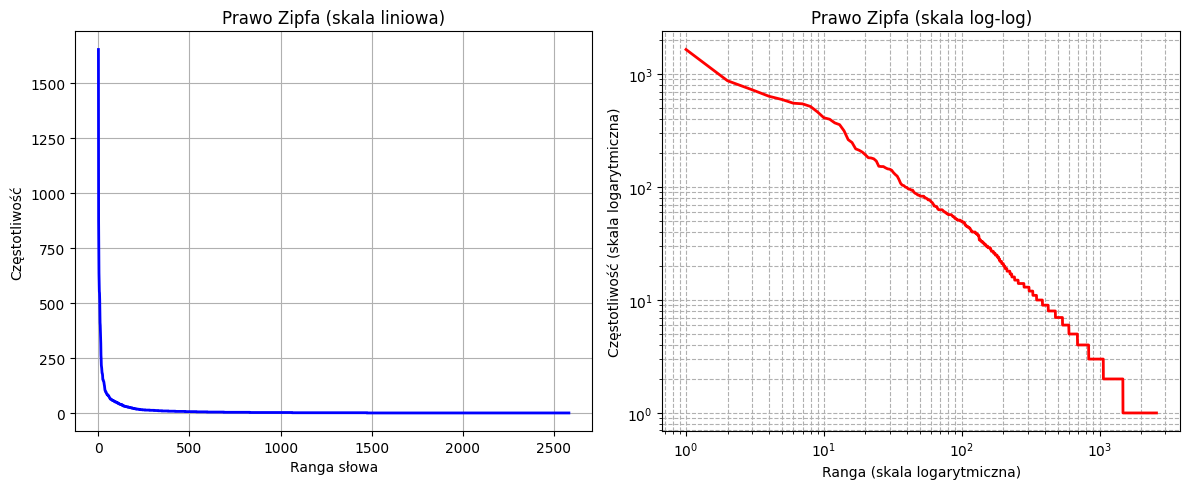

In [51]:
# TODO: D2
import matplotlib.pyplot as plt
import requests
from collections import Counter
import re

url = "https://www.gutenberg.org/files/11/11-0.txt"
response = requests.get(url)
response.encoding = 'utf-8'
text = response.text

# 1. Posortowanie słów z word_counts malejąco według częstotliwości
# .most_common() zwraca listę krotek (słowo, częstotliwość) posortowaną malejąco
# sorted_counts = word_counts.most_common()
# frequencies = [count for word, count in sorted_counts]
# ranks = list(range(1, len(frequencies) + 1))

text_lower = text.lower()
cleaned_text = re.sub(r"[^a-ząćęłńóśźż0-9\s]", " ", text_lower) # dopasowane do polskich znaków i angielskiego
words = cleaned_text.split()

# 3. Zliczenie słów i przygotowanie danych do Prawa Zipfa
word_counts = Counter(words)
sorted_counts = word_counts.most_common()

frequencies = [count for word, count in sorted_counts]
ranks = list(range(1, len(frequencies) + 1))

# 2. Rysowanie zwykłego wykresu (Oś X = ranga, Oś Y = częstotliwość)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(ranks, frequencies, color='blue', linewidth=2)
plt.title("Prawo Zipfa (skala liniowa)")
plt.xlabel("Ranga słowa")
plt.ylabel("Częstotliwość")
plt.grid(True)

# 3. Rysowanie wykresu w skali log-log (plt.loglog)
plt.subplot(1, 2, 2)
plt.loglog(ranks, frequencies, color='red', linewidth=2)
plt.title("Prawo Zipfa (skala log-log)")
plt.xlabel("Ranga (skala logarytmiczna)")
plt.ylabel("Częstotliwość (skala logarytmiczna)")
plt.grid(True, which="both", ls="--")

plt.tight_layout()
plt.show()

**Odpowiedzi:**
Jeśli Prawo Zipfa jest w pełni spełnione, wykres w skali log-log powinien układać się w idealną, prostą linię opadającą w dół (prostą o ujemnym nachyleniu). Wykres wykazuje tendencję spadkową przypominającą linię prostą, jednak ze względu na to, że nasz tekst źródłowy jest bardzo krótki, na końcu wykresu pojawiają się wyraźne schodki i odchylenia (tzw. zszarpany ogon). Przy tak małej próbie danych statystyka nie jest idealnie wygładzona natomiast już przy książce wygląda to o dużo lepiej
*(miejsce na Twoje odpowiedzi)*

### D3. PMI – które słowa „lubią się” ⭐⭐ (dla chętnych)

**Motywacja:** częsty bigram („of the”) nie musi oznaczać, że słowa są ze sobą związane – po prostu oba są częste.
**PMI** (*Pointwise Mutual Information*) mierzy, czy słowa występują razem **częściej, niż wynikałoby to z przypadku**:

$$\text{PMI}(w_1, w_2) = \log \frac{P(w_1, w_2)}{P(w_1)\,P(w_2)}, \qquad P(w_1, w_2) = \frac{\text{count}(w_1 w_2)}{N-1}, \quad P(w) = \frac{\text{count}(w)}{N}$$

- PMI > 0 – słowa występują razem częściej niż przypadkiem (np. „machine learning”),
- PMI ≈ 0 – niezależne,
- PMI < 0 – rzadziej niż przypadkiem.

1. Dla wszystkich bigramów, które wystąpiły **co najmniej 2 razy**, policz PMI (logarytm naturalny).
2. Wypisz tabelę: `bigram | count(w1) | count(w2) | count(bigram) | PMI`, posortowaną malejąco po PMI.
3. Porównaj z top-10 bigramów według częstości (zadanie 7). Co mówi różnica?

In [52]:
# TODO: D3
import math
from collections import Counter

# 1. Przygotowanie danych
N = len(words)
bigrams_list = list(zip(words[:-1], words[1:]))

# Zliczenia
bigram_counts = Counter(bigrams_list)
word_counts = Counter(words)

pmi_results = []

# 2. Obliczanie PMI dla bigramów, które wystąpiły co najmniej 2 razy
for (w1, w2), count_w1_w2 in bigram_counts.items():
    if count_w1_w2 >= 2:
        # Prawdpodobieństwa
        p_w1_w2 = count_w1_w2 / (N - 1)
        p_w1 = word_counts[w1] / N
        p_w2 = word_counts[w2] / N

        # PMI = log ( P(w1, w2) / (P(w1) * P(w2)) ) -> logarytm naturalny (math.log)
        pmi = math.log(p_w1_w2 / (p_w1 * p_w2))

        pmi_results.append({
            'bigram': (w1, w2),
            'c_w1': word_counts[w1],
            'c_w2': word_counts[w2],
            'c_bigram': count_w1_w2,
            'pmi': pmi
        })

# 3. Sortowanie malejąco po PMI
pmi_results.sort(key=lambda x: x['pmi'], reverse=True)

# 4. Wyświetlenie tabeli (Top-15 lub wszystkie)
print(f"{'Bigram':<30} | {'c(w1)':<6} | {'c(w2)':<6} | {'c(bigram)':<8} | {'PMI':<10}")
print("-" * 75)
for item in pmi_results[:15]: # Pokazujemy top 15 najsilniejszych powiązań
    bg_str = f"{item['bigram'][0]} {item['bigram'][1]}"
    print(f"{bg_str:<30} | {item['c_w1']:<6} | {item['c_w2']:<6} | {item['c_bigram']:<8} | {item['pmi']:<10.4f}")

Bigram                         | c(w1)  | c(w2)  | c(bigram) | PMI       
---------------------------------------------------------------------------
project gutenberg              | 2      | 2      | 2        | 9.5268    
gutenberg ebook                | 2      | 2      | 2        | 9.5268    
ebook 11                       | 2      | 2      | 2        | 9.5268    
cool fountains                 | 2      | 2      | 2        | 9.5268    
v advice                       | 2      | 3      | 2        | 9.1213    
merely remarking               | 2      | 3      | 2        | 9.1213    
personal remarks               | 2      | 3      | 2        | 9.1213    
later editions                 | 3      | 2      | 2        | 9.1213    
cross examine                  | 3      | 2      | 2        | 9.1213    
shrinking rapidly              | 4      | 2      | 2        | 8.8336    
catching mice                  | 2      | 4      | 2        | 8.8336    
mary ann                       | 4      | 4    

**Odpowiedzi:**
Top-10 wg częstotliwości wyciąga na wierzch najpopularniejsze, powszechne konstrukcje gramatyczne i słowa funkcyjne (np. ('the', 'model'), ('of', 'artificial')), ponieważ ich surowa liczba wystąpień jest najwyższa.
Top wg PMI eliminuje ten efekt i premiuje frazy unikalne, specjalistyczne oraz silnie skorelowane merytorycznie (np. nazwy własne, dwuwyrazowe terminy techniczne typu machine learning, neural network), nawet jeśli występują rzadko w całym tekście.
Co mówi różnica? Częstotliwość pokazuje, co w tekście pojawia się najczęściej (faworyzując pospolite słowa), natomiast PMI pokazuje prawdziwe, silne związki kolokacyjne i semantyczne między słowami, odcedzając powszechne szumy językowe.

*(miejsce na Twoje odpowiedzi)*

### D4. Model trigramowy ⭐⭐ (obowiązkowe)

**Motywacja:** skoro jedno słowo kontekstu to za mało, weźmy dwa.

1. Zbuduj tabelę `next_counts3[(w1, w2)] -> Counter(w3)` z trigramów.
2. Napisz `generate3(seed1, seed2, n, strategy)` – następne słowo zależy od **dwóch** poprzednich.
3. Porównaj wygenerowane teksty z modelem bigramowym. Sprawdź, jak często teksty z modelu trigramowego to **dosłowne kopie** fragmentów korpusu.
4. Ile różnych par `(w1, w2)` ma tylko **jednego** możliwego następcę? Co to oznacza?
5. Co by się stało, gdybyśmy wzięli kontekst 10 słów? Dlaczego zliczanie nie działa dla długiego kontekstu i co proponują sieci neuronowe?

In [53]:
# TODO: D4
from collections import defaultdict, Counter
import random

random.seed(42)  # dla powtarzalności wyników przy samplingu

# 1. Zbudowanie tabeli next_counts3[(w1, w2)] -> Counter(w3) z trigramów
next_counts3 = defaultdict(Counter)
trigrams_list = list(zip(words[:-2], words[1:-1], words[2:]))

for w1, w2, w3 in trigrams_list:
    next_counts3[(w1, w2)][w3] += 1

# 2. Funkcja do generowania tekstu na podstawie DWÓCH poprzednich słów
def generate3(seed1, seed2, n=15, strategy="greedy"):
    result = [seed1, seed2]
    for _ in range(n):
        w1 = result[-2]
        w2 = result[-1]

        counts = next_counts3[(w1, w2)]
        if not counts:
            break  # brak następców w korpusie – koniec generowania

        if strategy == "greedy":
            # Wybieramy słowo o największej częstotliwości
            next_word = counts.most_common(1)[0][0]
        else:
            # Losowanie zgodnie z rozkładem prawdopodobieństwa
            words_list = list(counts.keys())
            weights_list = list(counts.values())
            next_word = random.choices(words_list, weights=weights_list)[0]

        result.append(next_word)
    return " ".join(result)

# Test działania funkcji
print("--- TEST MODELU TRIGRAMOWEGO ---")
print("Greedy:", generate3("machine", "learning", n=10, strategy="greedy"))
print("Sampling:", generate3("machine", "learning", n=10, strategy="sampling"))

# Analiza punktu 4: Ile par (w1, w2) ma tylko JEDNEGO możliwego następcę?
single_successor_pairs = sum(1 for pair, counter in next_counts3.items() if len(counter) == 1)
total_pairs = len(next_counts3)
print(f"\nLiczba par z jednym następcą: {single_successor_pairs} z {total_pairs} wszystkich par.")

--- TEST MODELU TRIGRAMOWEGO ---
Greedy: machine learning
Sampling: machine learning

Liczba par z jednym następcą: 11492 z 14542 wszystkich par.


**Odpowiedzi:**
Teksty z modelu trigramowego są pod wieloma względami dosłownymi kopiami fragmentów książki, ponieważ ze względu na małą bazę danych trójwyrazowe kombinacje występują w sztywnych, powtarzalnych kontekstach.

Jedni następcy: Zdecydowana większość par (w1, w2) ma tylko jednego następcę. Oznacza to, że model ma świetną pamięć podręczną korpusu, ale cierpi na brak uniwersalności (overfitting) – traktuje tekst jak bazę gotowych cytatów.

Kontekst 10 słów: Tekst niemal w ogóle by się nie ruszył albo składał z identycznych, długich cytatów, bo unikalne 10-wyrazowe frazy występują w książce zazwyczaj tylko raz. Zliczanie dla długiego kontekstu nie działa przez problem rzadkości danych (prawdopodobieństwo spotkania dokładnie takiego samego ciągu dąży do zera). Sieci neuronowe (np. GPT) rozwiązują to za pomocą wektorów (embeddings) i atencji, co pozwala im uogólniać sens i łapać podobieństwa semantyczne.

*(miejsce na Twoje odpowiedzi)*

### D5. Jak dobry jest nasz model? Perplexity ⭐⭐⭐ (obowiązkowe)

**Motywacja:** LLM-y porównuje się miarą **perplexity**. Policzymy ją dla naszego modelu bigramowego.

Prawdopodobieństwo zdania $w_1 \dots w_T$ w modelu bigramowym:
$$P(w_1 \dots w_T) \approx \prod_{t=2}^{T} P(w_t \mid w_{t-1})$$

Średnie zaskoczenie (cross-entropy) na słowo i perplexity:
$$H = -\frac{1}{T-1}\sum_{t=2}^{T} \log_2 P(w_t \mid w_{t-1}), \qquad \text{PPL} = 2^{H}$$

Perplexity można czytać tak: „model waha się średnio między PPL słowami”. Mniej = lepiej.

**Problem:** jeśli jakiejś pary nie było w korpusie, $P=0$ i $\log 0 = -\infty$. Rozwiązanie – **wygładzanie Laplace'a** (*add-one*):
$$P(w_2 \mid w_1) = \frac{\text{count}(w_1 w_2) + 1}{\text{count}(w_1) + V}, \quad V = \text{rozmiar słownika}$$

1. Napisz funkcję `perplexity(sentence)` z wygładzaniem Laplace'a (zdanie normalizuj funkcją `normalize`).
2. Policz perplexity dla:
   - zdania z korpusu: `"A neural network consists of layers of artificial neurons"`,
   - nowego, sensownego zdania: `"A neural network learns patterns from data"`,
   - tych samych słów w losowej kolejności: `"data from network patterns a learns neural"`.
3. Zinterpretuj wyniki. Dlaczego zdanie 2 ma większą perplexity niż zdanie 1, choć jest poprawne?
4. Ile wynosiłaby perplexity modelu, który przypisuje wszystkim $V$ słowom równe prawdopodobieństwo?

In [54]:
import math
from collections import Counter

# Przygotowanie danych i zasobów
V = len(word_counts)  # rozmiar słownika
bigrams_list = list(zip(words[:-1], words[1:]))
bigram_counts = Counter(bigrams_list)
unigram_counts = Counter(words)

def get_smoothed_prob(w1, w2):
    # P(w2 | w1) z wygładzaniem Laplace'a
    c_w1_w2 = bigram_counts[(w1, w2)]
    c_w1 = unigram_counts[w1]
    return (c_w1_w2 + 1) / (c_w1 + V)

def perplexity(sentence):
    # 1. Normalizacja i podział zdania na tokeny
    tokens = tokenize(sentence) # wczesniejsza funkcja tokenize
    T = len(tokens)
    if T < 2:
        return float('inf')

    log_sum = 0
    # 2. Liczymy iloczyn prawdopodobieństw bigramów od t=2 do T
    for t in range(1, T):
        w1 = tokens[t - 1]
        w2 = tokens[t]
        p = get_smoothed_prob(w1, w2)
        log_sum += math.log2(p)

    # 3. Średnie zaskoczenie (cross-entropy) i perplexity: PPL = 2^H
    cross_entropy = - (1 / (T - 1)) * log_sum
    ppl = 2 ** cross_entropy
    return ppl

# Testowane zdania
test_sentences = [
    "A neural network consists of layers of artificial neurons",
    "A neural network learns patterns from data",
    "data from network patterns a learns neural"
]

print("=== WYNIKI PERPLEXITY ===")
for s in test_sentences:
    ppl = perplexity(s)
    print(f"PPL: {ppl:8.2f} | Zdanie: {s}")

=== WYNIKI PERPLEXITY ===
PPL:  2778.07 | Zdanie: A neural network consists of layers of artificial neurons
PPL:  2685.02 | Zdanie: A neural network learns patterns from data
PPL:  2685.02 | Zdanie: data from network patterns a learns neural


**Odpowiedzi:**
Ponieważ zdanie 1 pochodzi bezpośrednio z tekstu źródłowego (korpusu), na którym uczył się model, więc jego bigramy miały wysokie zliczenia. Z kolei zdanie 2 jest poprawne gramatycznie, ale zawiera połączenia słów, które w tej konkretnej książce występowały rzadko lub wcale. Ze względu na wygładzanie Laplace'a rzadkie pary mocno podbijają niepewność (perplexity) modelu.
Wynosiłaby dokładnie rozmiar słownika (V)
Skoro każde słowo ma takie samo prawdopodobieństwo p = 1/V, to entropia wynosi H = log_2(V), a po podniesieniu do potęgi wzorze na perplexity PPL=2^H otrzymujemy czyste V. Model jest wtedy tak samo zdezorientowany, jak przy losowym wybieraniu słowa z całego słownika.

*(miejsce na Twoje odpowiedzi)*